# **Initialization**

In [ ]:
!pip install nltk

In [ ]:
import os
import pandas as pd
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [ ]:
!unzip /content/balanced-reviews.zip

unzip:  cannot find or open /content/balanced-reviews.zip, /content/balanced-reviews.zip.zip or /content/balanced-reviews.zip.ZIP.


In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/balanced-reviews.txt",
    sep="\t",
    encoding="utf-16"
)

print(df.head())

   no Hotel name  rating    user type                   room type  \
0   2    فندق 72       2  مسافر منفرد  غرفة ديلوكس مزدوجة أو توأم   
1   3    فندق 72       5          زوج  غرفة ديلوكس مزدوجة أو توأم   
2  16    فندق 72       5          زوج                           -   
3  20    فندق 72       1          زوج          غرفة قياسية مزدوجة   
4  23    فندق 72       4          زوج  غرفة ديلوكس مزدوجة أو توأم   

            nights                                             review  
0  أقمت ليلة واحدة                  “ممتاز”. النظافة والطاقم متعاون.   
1  أقمت ليلة واحدة  استثنائي. سهولة إنهاء المعاملة في الاستقبال. ل...  
2      أقمت ليلتين  استثنائي. انصح بأختيار الاسويت و بالاخص غرفه ر...  
3  أقمت ليلة واحدة  “استغرب تقييم الفندق كخمس نجوم”. لا شي. يستحق ...  
4      أقمت ليلتين  جيد. المكان جميل وهاديء. كل شي جيد ونظيف بس كا...  


In [ ]:
print(df.columns)

Index(['no', 'Hotel name', 'rating', 'user type', 'room type', 'nights',
       'review'],
      dtype='object')


In [ ]:
df_imp = df[['review', 'rating']]
df_imp.head()

,review,rating
0,“ممتاز”. النظافة والطاقم متعاون.,2
1,استثنائي. سهولة إنهاء المعاملة في الاستقبال. ل...,5
2,استثنائي. انصح بأختيار الاسويت و بالاخص غرفه ر...,5
3,“استغرب تقييم الفندق كخمس نجوم”. لا شي. يستحق ...,1
4,جيد. المكان جميل وهاديء. كل شي جيد ونظيف بس كا...,4


In [ ]:
df_imp["rating"] = df_imp["rating"].map({
    5: "positive",
    4: "positive",
    1: "negative",
    2: "negative"
})
df_imp.head()

/tmp/ipykernel_5738/3063876886.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_imp["rating"] = df_imp["rating"].map({


,review,rating
0,“ممتاز”. النظافة والطاقم متعاون.,negative
1,استثنائي. سهولة إنهاء المعاملة في الاستقبال. ل...,positive
2,استثنائي. انصح بأختيار الاسويت و بالاخص غرفه ر...,positive
3,“استغرب تقييم الفندق كخمس نجوم”. لا شي. يستحق ...,negative
4,جيد. المكان جميل وهاديء. كل شي جيد ونظيف بس كا...,positive


In [ ]:
from sklearn.model_selection import train_test_split

X = df_imp['review']
y = df_imp['rating']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# **Text-Preprocessing level 1**

In [ ]:
nltk.download('stopwords')
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
import nltk
from nltk.corpus import stopwords

stop_words = set(stopwords.words('arabic'))

more_stopwords = ['.', "”", "“", "،"]
stop_words.update(more_stopwords)

# Arabic negation words to preserve
negation_words = {
    "لا",
    "ليس",
    "ليست",
    "لست",
    "لسنا",
    "لستم",
    "لم",
    "لن",
    "ما",
    "مو",
    "مش",
}

# Make sure negation words are NOT removed
stop_words.difference_update(negation_words)


def remove_stopwords(text):
    words = nltk.word_tokenize(text)

    filtered_words = [
        word for word in words
        if word not in stop_words
    ]

    return " ".join(filtered_words)


print("Filtering X_train...")
X_train = X_train.apply(remove_stopwords)

print("Filtering X_test...")
X_test = X_test.apply(remove_stopwords)

print(X_train.head())

Filtering X_train...
Filtering X_test...
84826          الشعباني موقعه بعيد الخدمات والمرافق العامة
91845    شئ جميل وتجربة رائعة لهذا الفندق وسأعاود الاقا...
45021    بسيط تعامل الموظفين استقبال الدخول الباب الرئي...
71270          جيد لا يوجد الحوض السباحه المفروض يكون اكبر
96126    فندق رائع حسن تعامل طاقم العمل + الترتيب موقع ...
Name: review, dtype: object


In [ ]:
import re

def remove_html_and_urls(text):
    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)
    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    return text

X_train = X_train.apply(remove_html_and_urls)
X_test = X_test.apply(remove_html_and_urls)
X_train.head()

,review
84826,الشعباني موقعه بعيد الخدمات والمرافق العامة
91845,شئ جميل وتجربة رائعة لهذا الفندق وسأعاود الاقا...
45021,بسيط تعامل الموظفين استقبال الدخول الباب الرئي...
71270,جيد لا يوجد الحوض السباحه المفروض يكون اكبر
96126,فندق رائع حسن تعامل طاقم العمل + الترتيب موقع ...


In [ ]:
%%capture
!pip install num2words

In [ ]:
from num2words import num2words

In [ ]:
def convert_numbers_to_words(text):
    return re.sub(
        r"\d+",
        lambda match: num2words(int(match.group()), lang="ar"),
        text
    )

X_train = X_train.apply(convert_numbers_to_words)
X_test = X_test.apply(convert_numbers_to_words)
X_train.head()

,review
84826,الشعباني موقعه بعيد الخدمات والمرافق العامة
91845,شئ جميل وتجربة رائعة لهذا الفندق وسأعاود الاقا...
45021,بسيط تعامل الموظفين استقبال الدخول الباب الرئي...
71270,جيد لا يوجد الحوض السباحه المفروض يكون اكبر
96126,فندق رائع حسن تعامل طاقم العمل + الترتيب موقع ...


In [ ]:
def remove_prefixes(text):
    # Remove repeated sequential letters
    text = re.sub(r'(.)\1+', r'\1', text)

    # Remove و from the beginning of a word
    text = re.sub(r'\bو', '', text)

    # Remove ك from the beginning of a word
    #text = re.sub(r'\bك', '', text)

    # Remove ك from the beginning of a word
    #text = re.sub(r'\bب', '', text)

    # Remove ك from the beginning of a word
    #text = re.sub(r'\bل', '', text)

    # Remove ال from the beginning of a word
    text = re.sub(r'\bال', '', text)

    return text

X_train = X_train.apply(remove_prefixes)
X_test = X_test.apply(remove_prefixes)
X_train.head()

,review
84826,شعباني موقعه بعيد خدمات مرافق عامة
91845,شئ جميل تجربة رائعة لهذا فندق سأعاود اقامة حال...
45021,بسيط تعامل موظفين استقبال دخول باب رئيسى استلا...
71270,جيد لا يوجد حوض سباحه مفروض يكون اكبر
96126,فندق رائع حسن تعامل طاقم عمل + ترتيب موقع فندق...


In [ ]:
def normalize_arabic(text):
    text = re.sub("[إأآا]", "ا", text)
    text = re.sub("ى", "ي", text)
    text = re.sub("ؤ", "و", text)
    text = re.sub("ئ", "ي", text)

    return text

X_train = X_train.apply(normalize_arabic)
X_test = X_test.apply(normalize_arabic)
X_train.head()

,review
84826,شعباني موقعه بعيد خدمات مرافق عامة
91845,شي جميل تجربة رايعة لهذا فندق ساعاود اقامة حال...
45021,بسيط تعامل موظفين استقبال دخول باب رييسي استلا...
71270,جيد لا يوجد حوض سباحه مفروض يكون اكبر
96126,فندق رايع حسن تعامل طاقم عمل + ترتيب موقع فندق...


In [ ]:
def remove_tashkeel_and_tatweel(text):
    # Remove Arabic diacritics (tashkeel)
    text = re.sub(r'[\u064B-\u065F\u0670]', '', text)

    # Remove tatweel
    text = text.replace('ـ', '')

    return text

X_train = X_train.apply(remove_tashkeel_and_tatweel)
X_test = X_test.apply(remove_tashkeel_and_tatweel)
X_train.head()

,review
84826,شعباني موقعه بعيد خدمات مرافق عامة
91845,شي جميل تجربة رايعة لهذا فندق ساعاود اقامة حال...
45021,بسيط تعامل موظفين استقبال دخول باب رييسي استلا...
71270,جيد لا يوجد حوض سباحه مفروض يكون اكبر
96126,فندق رايع حسن تعامل طاقم عمل + ترتيب موقع فندق...


/tmp/ipykernel_5738/3023550907.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Frequency', y='Word', data=df_positive, palette='viridis')
/tmp/ipykernel_5738/3023550907.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Frequency', y='Word', data=df_negative, palette='magma')


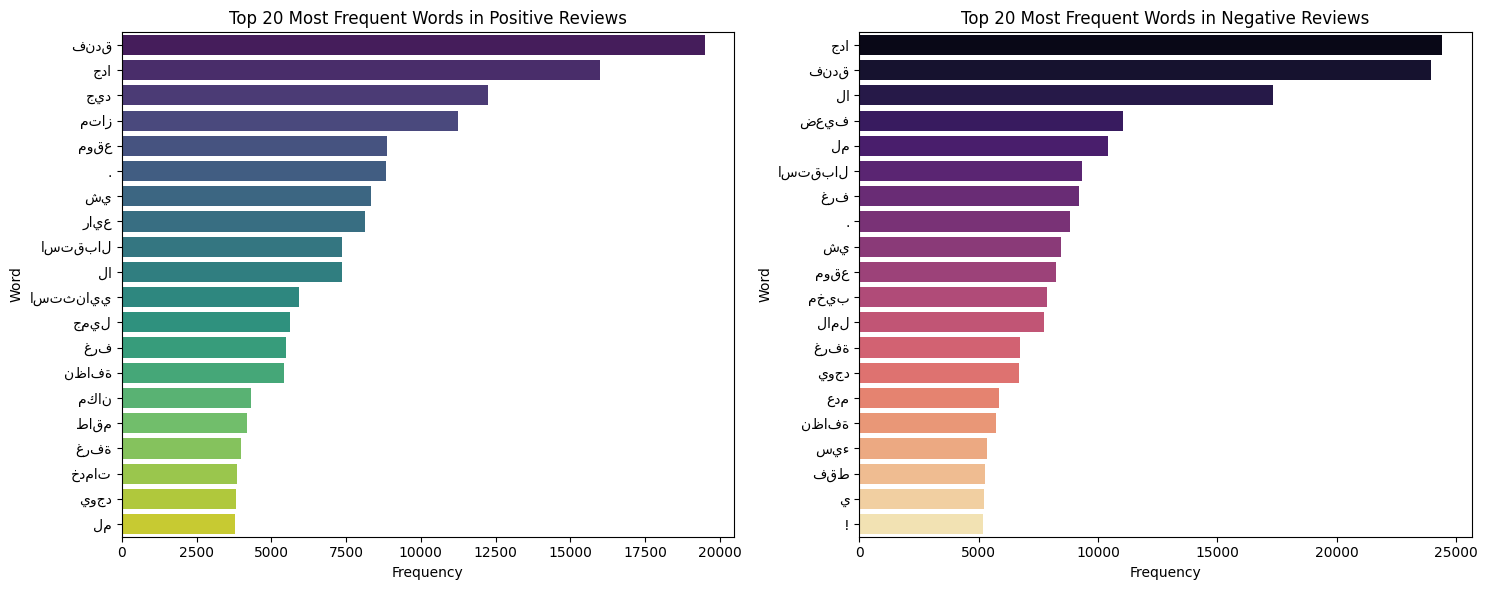

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict

# Separate reviews by sentiment
positive_reviews = X_train[y_train == 'positive']
negative_reviews = X_train[y_train == 'negative']

# Function to get word frequencies
def get_word_frequencies(reviews):
    all_words = []
    for review in reviews:
        # Ensure the review is treated as a string before tokenizing
        if isinstance(review, str):
            all_words.extend(nltk.word_tokenize(review))
    return nltk.FreqDist(all_words)

# Get word frequencies for each class
positive_word_freq = get_word_frequencies(positive_reviews)
negative_word_freq = get_word_frequencies(negative_reviews)

# Get the top N most common words
N = 20
top_positive_words = positive_word_freq.most_common(N)
top_negative_words = negative_word_freq.most_common(N)

# Create DataFrames for plotting
df_positive = pd.DataFrame(top_positive_words, columns=['Word', 'Frequency'])
df_negative = pd.DataFrame(top_negative_words, columns=['Word', 'Frequency'])

# Plotting
plt.figure(figsize=(15, 6))

# Top words for Positive Class
plt.subplot(1, 2, 1)
sns.barplot(x='Frequency', y='Word', data=df_positive, palette='viridis')
plt.title(f'Top {N} Most Frequent Words in Positive Reviews')
plt.xlabel('Frequency')
plt.ylabel('Word')

# Top words for Negative Class
plt.subplot(1, 2, 2)
sns.barplot(x='Frequency', y='Word', data=df_negative, palette='magma')
plt.title(f'Top {N} Most Frequent Words in Negative Reviews')
plt.xlabel('Frequency')
plt.ylabel('Word')

plt.tight_layout()
plt.show()

# **Text-Preprocessing level 2**

In [ ]:
!pip install gensim

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(ngram_range=(1, 3))

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Shape of X_train_tfidf:", X_train_tfidf.shape)
print("Shape of X_test_tfidf:", X_test_tfidf.shape)

Shape of X_train_tfidf: (84558, 2055713)
Shape of X_test_tfidf: (21140, 2055713)


# **Model Training**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder

# Encode target labels (positive/negative) to numerical (0/1) for LogisticRegression
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

# Initialize and train the Logistic Regression model
model = LogisticRegression(max_iter=1000) # Increased max_iter for convergence
model.fit(X_train_tfidf, y_train_encoded)

# Predict on the test set
y_pred_encoded = model.predict(X_test_tfidf)

# Convert numerical predictions back to original labels for the classification report
y_pred = le.inverse_transform(y_pred_encoded)

# Generate and print the classification report
print("\nClassification Report for Logistic Regression Model:")
report_dict = classification_report(y_test, y_pred, output_dict=True)

# Print formatted header
print(f"{'':<15}{'precision':>10}{'recall':>10}{'f1-score':>10}{'support':>10}")
print(f"{'':<15}{'-'*10:>10}{'-'*10:>10}{'-'*10:>10}{'-'*10:>10}")

# Print metrics for each class
for label_name in le.classes_:
    metrics = report_dict[label_name]
    print(f"{label_name:<15}{metrics['precision']:>10.2f}{metrics['recall']:>10.2f}{metrics['f1-score']:>10.2f}{metrics['support']:>10.0f}")

# Print line separator for averages
print(f"{'':<15}{'-'*10:>10}{'-'*10:>10}{'-'*10:>10}{'-'*10:>10}")

# Print accuracy (single value)
print(f"{'accuracy':<15}{'':>10}{'':>10}{report_dict['accuracy']:>10.2f}{report_dict['macro avg']['support']:>10.0f}")

# Print macro avg and weighted avg
for label_type in ['macro avg', 'weighted avg']:
    metrics = report_dict[label_type]
    print(f"{label_type:<15}{metrics['precision']:>10.2f}{metrics['recall']:>10.2f}{metrics['f1-score']:>10.2f}{metrics['support']:>10.0f}")


Classification Report for Logistic Regression Model:
                precision    recall  f1-score   support
               ----------------------------------------
negative             0.93      0.93      0.93     10493
positive             0.93      0.93      0.93     10647
               ----------------------------------------
accuracy                                 0.93     21140
macro avg            0.93      0.93      0.93     21140
weighted avg         0.93      0.93      0.93     21140
